# Clustering of Credit Card Customer Data
## 1. Create a scatterplot based on the dataset using two variables, namely Avg_Credit_Limit and Total_credit_card. Can the distribution of the data be considered linear?
## 2. Construct a clustering model using the K-Means algorithm. Determine the optimal number k using elbow method. Supplement your analysis with line chart and provide an analytical rationale for why you selected that value.
## 3. Depict the clustering results from the K-Means model using a scatter plot.
## 4. Construct a clustering model using DBSCAN with all usable variables.
## 5. Determine the number k using elbow method. Supplement your analysis with line chart and provide an analytical rationale for why you selected that value.
## 6. Determine the value of the silhouette score and the DBI of the DBSCAN model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')
print(df.head())
print(df.info())

   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  
<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   C

## 1. Scatterplot of Avg_Credit_Limit vs Total_Credit_Cards & Linearity Analysis

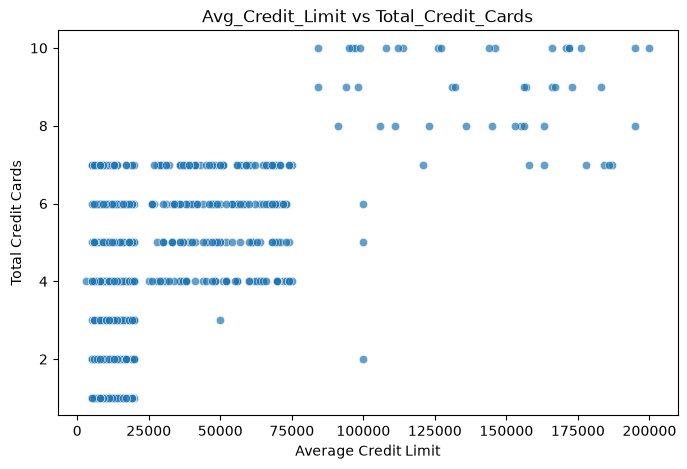

In [2]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards', alpha=0.7)
plt.title('Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.show()

**Analysis for Question 1:**
No, the distribution cannot be considered linear. The data points form distinct horizontal tiers and vertical clusters rather than following a continuous straight-line correlation.

## 2 & 3. K-Means Clustering & Optimal k (Elbow Method) and Scatter Plot Visualization

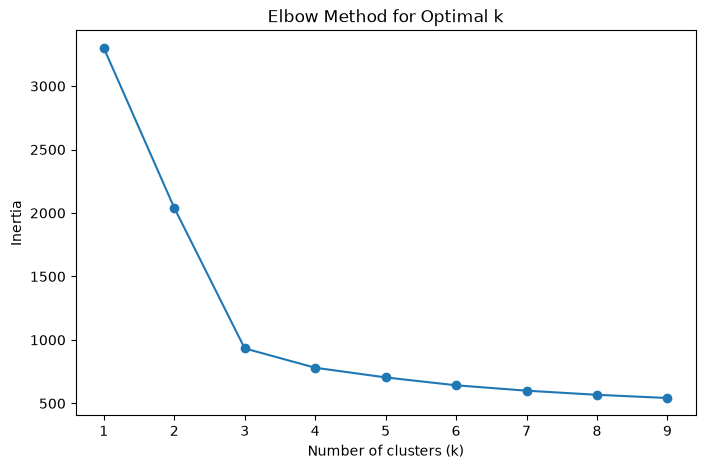

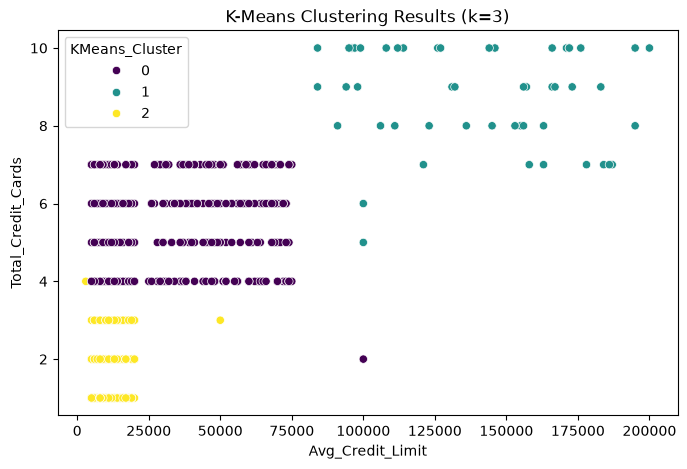

In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Feature selection & scaling
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow Method
inertia = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

# Fit K-Means with optimal k = 3
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Visualize K-Means Clustering Results
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards', hue='KMeans_Cluster', palette='viridis')
plt.title(f'K-Means Clustering Results (k={optimal_k})')
plt.show()

## 4, 5 & 6. DBSCAN Clustering Model, Parameter Tuning, and Evaluation Metrics

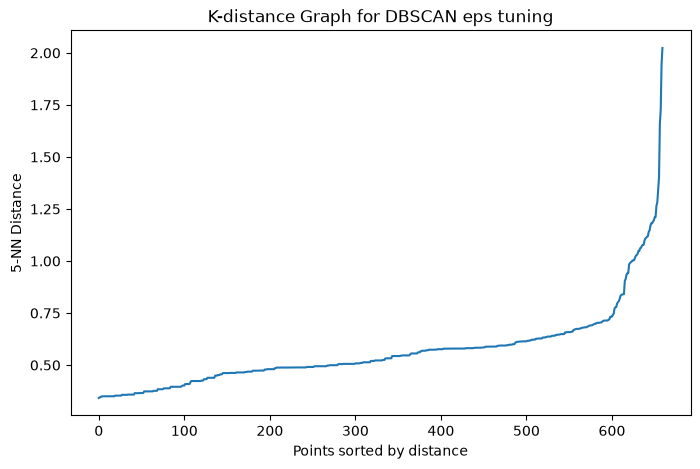

Estimated number of clusters: 3
Estimated number of noise points: 46
Silhouette Score: 0.4901
Davies-Bouldin Index (DBI): 0.6993


In [4]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# K-distance graph for eps tuning
neigh = NearestNeighbors(n_neighbors=5)
neigh.fit(X_scaled)
distances, indices = neigh.kneighbors(X_scaled)
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-distance Graph for DBSCAN eps tuning')
plt.xlabel('Points sorted by distance')
plt.ylabel('5-NN Distance')
plt.show()

# Construct DBSCAN model with optimal parameters (eps=0.7, min_samples=3)
dbscan = DBSCAN(eps=0.7, min_samples=3)
dbscan_labels = dbscan.fit_predict(X_scaled)
df['DBSCAN_Cluster'] = dbscan_labels

# Evaluation metrics (excluding noise points labeled as -1)
non_noise_mask = dbscan_labels != -1
n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_db = list(dbscan_labels).count(-1)

print(f"Estimated number of clusters: {n_clusters_db}")
print(f"Estimated number of noise points: {n_noise_db}")

if n_clusters_db > 1:
    sil_score = silhouette_score(X_scaled[non_noise_mask], dbscan_labels[non_noise_mask])
    dbi_score = davies_bouldin_score(X_scaled[non_noise_mask], dbscan_labels[non_noise_mask])
    print(f"Silhouette Score: {sil_score:.4f}")
    print(f"Davies-Bouldin Index (DBI): {dbi_score:.4f}")